In [4]:
from google.colab import files

uploaded = files.upload()

Saving banking_transactions.csv to banking_transactions.csv


Dataset loaded successfully!
  Customer_ID Age_Group Occupation        City  UPI_Count  Card_Count  \
0        C001     18-25    Student     Chennai         45          10   
1        C002     26-35         IT     Chennai         60          25   
2        C003     36-50   Business  Coimbatore         20          35   
3        C004       51+    Retired     Madurai          5          10   
4        C005     18-25    Student       Salem         55           8   

   ATM_Count  Deposits  Withdrawals  Bill_Payments  
0          2     15000         5000              4  
1          3     50000        18000              8  
2         15     80000        45000             10  
3         25     40000        20000              6  
4          1     12000         4000              3  
Shape: (20, 10)

Digital Preference:
Digital_Preference
Digital        15
Traditional     5
Name: count, dtype: int64

Average ATM Usage:
Age_Group
18-25     1.6
26-35     5.4
36-50    11.0
51+      26.2
Name: ATM_

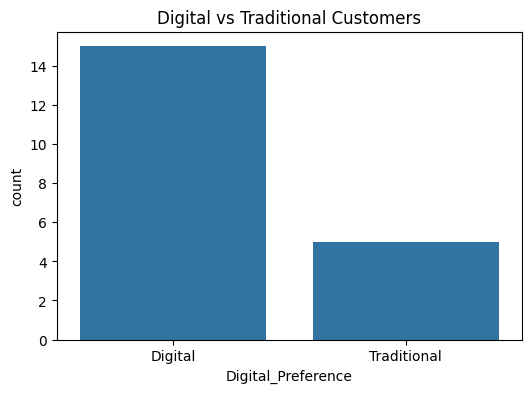

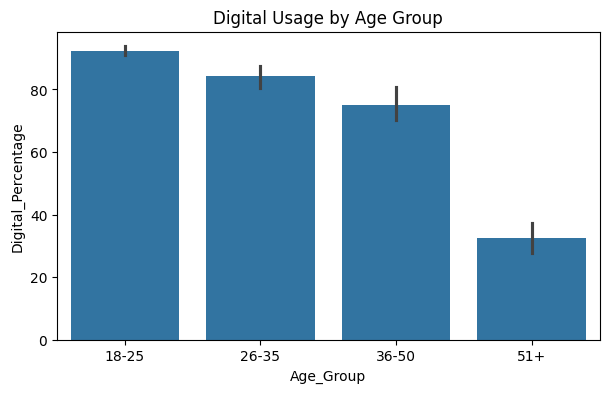

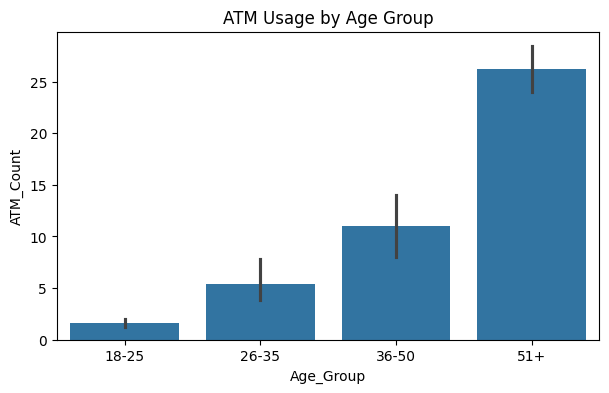

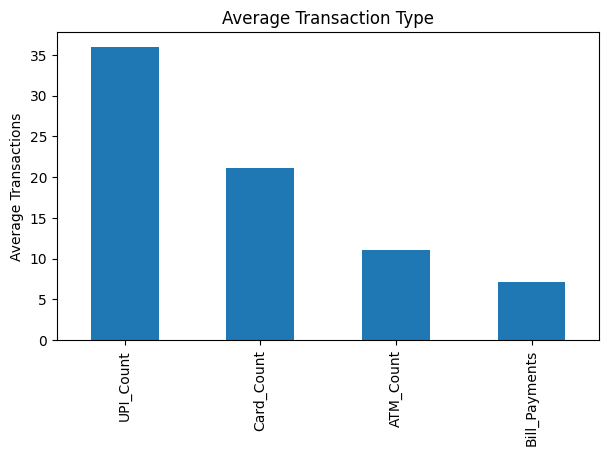


KNN Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
df = pd.read_csv("banking_transactions.csv")

print("Dataset loaded successfully!")
print(df.head())
print("Shape:", df.shape)

# Create features
df["Digital_Transactions"] = df["UPI_Count"] + df["Card_Count"]

df["Total_Transactions"] = (
    df["UPI_Count"] +
    df["Card_Count"] +
    df["ATM_Count"] +
    df["Bill_Payments"]
)

df["Digital_Percentage"] = (
    df["Digital_Transactions"] /
    df["Total_Transactions"]
) * 100

# Digital / Traditional
df["Digital_Preference"] = df["Digital_Percentage"].apply(
    lambda x: "Digital" if x >= 50 else "Traditional"
)

# Analysis
print("\nDigital Preference:")
print(df["Digital_Preference"].value_counts())

print("\nAverage ATM Usage:")
print(df.groupby("Age_Group")["ATM_Count"].mean())

print("\nAverage Digital Usage:")
print(df.groupby("Age_Group")["Digital_Percentage"].mean())

# Graph 1
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Digital_Preference")
plt.title("Digital vs Traditional Customers")
plt.show()

# Graph 2
plt.figure(figsize=(7,4))
sns.barplot(data=df, x="Age_Group", y="Digital_Percentage")
plt.title("Digital Usage by Age Group")
plt.show()

# Graph 3
plt.figure(figsize=(7,4))
sns.barplot(data=df, x="Age_Group", y="ATM_Count")
plt.title("ATM Usage by Age Group")
plt.show()

# Graph 4
plt.figure(figsize=(7,4))
df[["UPI_Count", "Card_Count", "ATM_Count", "Bill_Payments"]].mean().plot(
    kind="bar"
)
plt.title("Average Transaction Type")
plt.ylabel("Average Transactions")
plt.show()

# ---------------- KNN ----------------

X = df[
    [
        "UPI_Count",
        "Card_Count",
        "ATM_Count",
        "Deposits",
        "Withdrawals",
        "Bill_Payments"
    ]
]

y = df["Digital_Preference"].map({
    "Traditional": 0,
    "Digital": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# KNN
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

# Prediction
y_pred = knn.predict(X_test)

# Evaluation
print("\nKNN Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))